# Neutralização e titulação ácido-base
### Funções inorgânicas — bases

**Objetivo:** Usar $c_aV_a a = c_bV_b b$, traçar a curva de titulação e escolher o indicador certo para o ponto de equivalência.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

A **neutralização** é a reação entre um ácido e uma base, cujo resultado é sal e água:

$$
\boxed{\mathrm{HA + BOH \rightarrow BA + H_2O}}
$$

Do ponto de vista iônico, o que acontece de verdade é a formação de água a partir dos íons:

$$
\mathrm{H^+ + OH^- \rightarrow H_2O}, \qquad \Delta H \approx -57{,}3\ \mathrm{kJ/mol}
$$

A reação é exotérmica: neutralizar libera calor (é a base do "bolsinha quente" de algumas compressas).

Na **titulação**, a relação fundamental é a igualdade de equivalentes:

$$
\boxed{n_{\mathrm{H^+}} = n_{\mathrm{OH^-}}}
\qquad\Rightarrow\qquad
c_a V_a \cdot a = c_b V_b \cdot b
$$

em que $a$ e $b$ são o número de prótons e de hidroxilas por fórmula. O ponto em que isso acontece é o **ponto de equivalência**; o indicador é escolhido para mudar de cor perto desse pH.

## 2. Exemplo resolvido passo a passo

Titular $25{,}0\ \mathrm{mL}$ de $\mathrm{H_2SO_4}$ com $\mathrm{NaOH}$ $0{,}200\ \mathrm{mol/L}$; gastaram-se $20{,}0\ \mathrm{mL}$ de base.

**Passo 1 — mols de base.**

$$
n_b = c_b V_b = 0{,}200 \cdot 0{,}0200 = 4{,}00\times10^{-3}\ \mathrm{mol}
$$

**Passo 2 — mols de ácido ($b=1$, $a=2$).**

$$
n_a = \frac{n_b}{2} = 2{,}00\times10^{-3}\ \mathrm{mol}
$$

**Passo 3 — concentração do ácido.**

$$
c_a = \frac{n_a}{V_a} = \frac{2{,}00\times10^{-3}}{0{,}0250} = \boxed{0{,}080\ \mathrm{mol/L}}
$$

**Passo 4 — pH no ponto de equivalência.**

O sal formado é $\mathrm{Na_2SO_4}$, derivado de ácido forte e base forte: sofre hidrólise desprezível. Logo

$$
\mathrm{pH} = \boxed{7{,}0}
$$

Se fosse ácido fraco com base forte, o sal seria básico (hidrólise do ânion) e o pH no ponto de equivalência passaria de 7.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Cálculo da titulação
CA_NAOH = 0.200     # mol/L
VA_NAOH = 20.0e-3   # L
V_ACIDO = 25.0e-3   # L
A_PROTONS = 2       # H2SO4

n_base = CA_NAOH * VA_NAOH
n_acido = n_base / A_PROTONS
c_acido = n_acido / V_ACIDO

print(f"n(NaOH)    = {n_base:.2e} mol")
print(f"n(H2SO4)   = {n_acido:.2e} mol")
print(f"c(H2SO4)   = {c_acido:.3f} mol/L")
print(f"massa de H2SO4 na alíquota = {n_acido * 98.08 * 1000:.1f} mg")
print("pH no ponto de equivalência: 7,0 (sal de ácido forte + base forte)")

n(NaOH)    = 4.00e-03 mol
n(H2SO4)   = 2.00e-03 mol
c(H2SO4)   = 0.080 mol/L
massa de H2SO4 na alíquota = 196.2 mg
pH no ponto de equivalência: 7,0 (sal de ácido forte + base forte)


## 4. Visualização

### 4.1 O ácido sulfúrico em 3D — arraste para girar

É o ácido diprótico do exemplo: dois $-OH$ e dois $\mathrm{S=O}$. Gire para ver o arranjo tetraédrico em torno do enxofre.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("OS(=O)(=O)O")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 O sal formado: sulfato de sódio em 3D

O produto da neutralização é o $\mathrm{Na_2SO_4}$ — dois cátions sódio para balancear o ânion sulfato $\mathrm{SO_4^{2-}}$. O 3D mostra a proporção 2:1.

In [4]:
molecula_3d("[Na+].[Na+].[O-]S(=O)(=O)[O-]")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

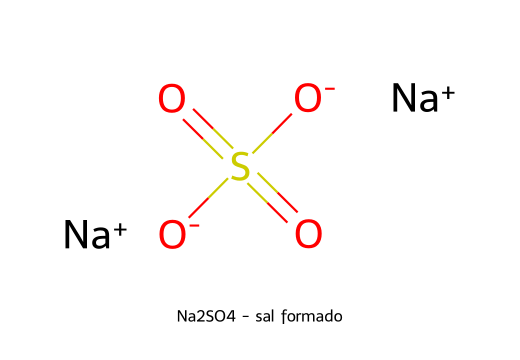

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("OS(=O)(=O)O", legenda="H2SO4 - acido (2 H+)")
estrutura_2d("[Na+].[Na+].[O-]S(=O)(=O)[O-]", legenda="Na2SO4 - sal formado")

### 4.4 A curva de titulação — o gráfico mais importante do assunto

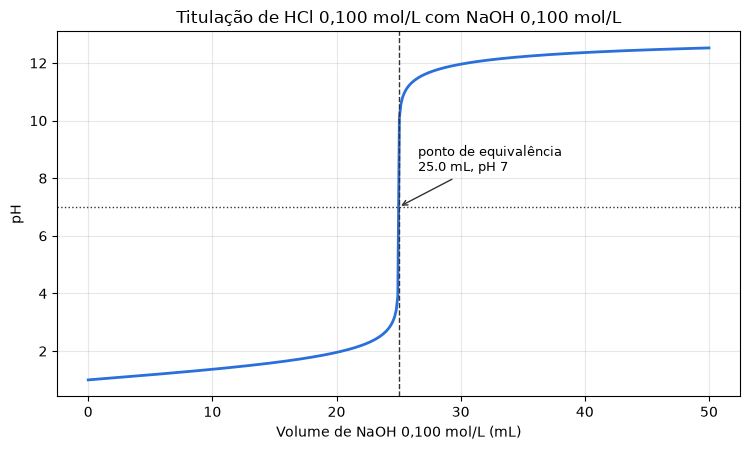

In [6]:
# @title Curva de titulação: ácido forte x base forte
import numpy as np
import matplotlib.pyplot as plt

def ph_titulacao_forte(c_acido, v_acido, c_base, v_base):
    """pH da mistura (ácido forte + base forte) em função do volume de base."""
    n_acido, n_base = c_acido * v_acido, c_base * v_base
    v = v_acido + np.asarray(v_base)
    excesso_acido = n_acido - n_base
    ph = np.where(excesso_acido > 0,
                  -np.log10(np.maximum(excesso_acido, 1e-15) / v),
                  14 + np.log10(np.maximum(-excesso_acido, 1e-15) / v))
    return np.clip(ph, 0, 14)

C_AC, V_AC = 0.100, 25.0e-3
C_BASE = 0.100
volumes = np.linspace(0, 2 * 25.0, 400) * 1e-3       # 0 a 50 mL
ph = ph_titulacao_forte(C_AC, V_AC, C_BASE, volumes)
v_eq = C_AC * V_AC / C_BASE

plt.figure(figsize=(7.6, 4.6))
plt.plot(volumes * 1000, ph, color="#2a6fdb", linewidth=2)
plt.axvline(v_eq * 1000, color="#333", linestyle="--", linewidth=1)
plt.axhline(7, color="#333", linestyle=":", linewidth=1)
plt.annotate(f"ponto de equivalência\n{v_eq * 1000:.1f} mL, pH 7",
             (v_eq * 1000, 7), xytext=(14, 26), textcoords="offset points",
             fontsize=9, arrowprops={"arrowstyle": "->", "color": "#333"})
plt.xlabel("Volume de NaOH 0,100 mol/L (mL)")
plt.ylabel("pH")
plt.title("Titulação de HCl 0,100 mol/L com NaOH 0,100 mol/L")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.5 A escolha do indicador

Cada indicador muda de cor numa faixa de pH. O indicador certo é aquele cuja virada **contém** o pH do ponto de equivalência.

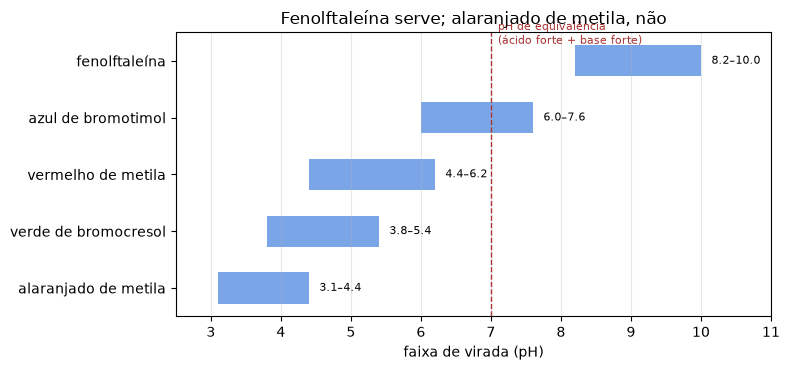

In [7]:
# @title Faixas dos indicadores
indicadores = [
    ("alaranjado de metila", 3.1, 4.4),
    ("verde de bromocresol", 3.8, 5.4),
    ("vermelho de metila", 4.4, 6.2),
    ("azul de bromotimol", 6.0, 7.6),
    ("fenolftaleína", 8.2, 10.0),
]

fig, eixo = plt.subplots(figsize=(8, 3.8))
for i, (nome, inicio, fim) in enumerate(indicadores):
    eixo.barh(i, fim - inicio, left=inicio, height=0.55, color="#7aa6e8")
    eixo.text(fim + 0.15, i, f"{inicio}–{fim}", va="center", fontsize=8)
eixo.set_yticks(range(len(indicadores)))
eixo.set_yticklabels([nome for nome, _, _ in indicadores])
eixo.axvline(7, color="#a33", linestyle="--", linewidth=1)
eixo.text(7.1, 4.3, "pH de equivalência\n(ácido forte + base forte)", fontsize=8, color="#a33")
eixo.set_xlim(2.5, 11)
eixo.set_xlabel("faixa de virada (pH)")
eixo.set_title("Fenolftaleína serve; alaranjado de metila, não")
eixo.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 Calor de neutralização

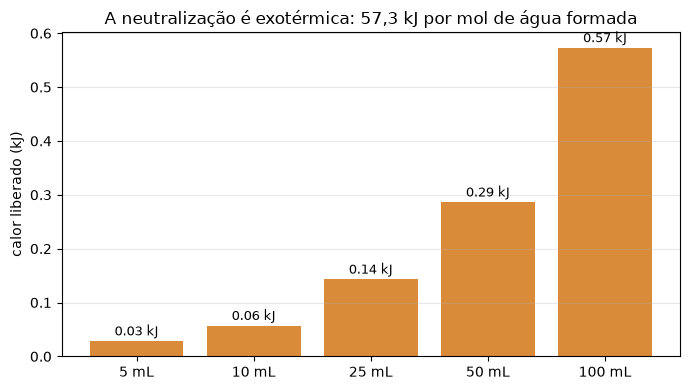

In [8]:
# @title Energia liberada
volumes_teste = np.array([5, 10, 25, 50, 100]) * 1e-3      # L de NaOH 0,100 mol/L
calor = volumes_teste * 0.100 * 57.3                      # kJ (entalpia por mol de água)

plt.figure(figsize=(7, 4))
plt.bar([f"{v * 1000:.0f} mL" for v in volumes_teste], calor, color="#d98b3a")
for i, valor in enumerate(calor):
    plt.annotate(f"{valor:.2f} kJ", (i, valor), xytext=(0, 4),
                 textcoords="offset points", ha="center", fontsize=9)
plt.ylabel("calor liberado (kJ)")
plt.title("A neutralização é exotérmica: 57,3 kJ por mol de água formada")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- A curva é **quase vertical** perto do ponto de equivalência: um décimo de mililitro muda o pH em várias unidades. É por isso que a bureta é graduada com cuidado.
- Indicador errado = erro de várias gotas. A fenolftaleína vira em 8,2–10,0, então serve para ácido forte + base forte; para ácido fraco + base forte o pH de equivalência é maior e ela é ainda melhor.
- O sal de ácido forte com base forte não hidrolisa: pH 7. Sal de ácido fraco com base forte fica básico; de ácido forte com base fraca, ácido.
- $\Delta H = -57{,}3\ \mathrm{kJ/mol}$ é constante porque, no fundo, a reação é sempre $\mathrm{H^+ + OH^- \rightarrow H_2O}$.

## 6. Exercício de fixação

$20{,}0\ \mathrm{mL}$ de $\mathrm{NH_3}$ $0{,}100\ \mathrm{mol/L}$ foram titulados com $\mathrm{HCl}$ $0{,}100\ \mathrm{mol/L}$. Qual o volume gasto no ponto de equivalência e o pH nesse ponto? (Para o $\mathrm{NH_4^+}$: $K_a = 5{,}6\times10^{-10}$.)

In [9]:
# @title Exercício
import math

C_NH3, V_NH3, C_HCl = 0.100, 20.0e-3, 0.100
KA_NH4 = 5.6e-10

v_eq = C_NH3 * V_NH3 / C_HCl
print(f"volume de HCl no ponto de equivalência: {v_eq * 1000:.1f} mL")

# No ponto de equivalência só existe NH4+ (ácido fraco): pH de sal ácido
c_sal = C_NH3 * V_NH3 / (V_NH3 + v_eq)
h = math.sqrt(KA_NH4 * c_sal)
print(f"[NH4+] no ponto = {c_sal:.4f} mol/L")
print(f"pH = {-math.log10(h):.2f}  (ácido: sal de base fraca com ácido forte)")

volume de HCl no ponto de equivalência: 20.0 mL
[NH4+] no ponto = 0.0500 mol/L
pH = 5.28  (ácido: sal de base fraca com ácido forte)


## 7. Resumo

- Neutralização: $\mathrm{ácido + base \rightarrow sal + água}$, exotérmica ($-57{,}3\ \mathrm{kJ/mol}$).
- $c_a V_a a = c_b V_b b$ resolve qualquer titulação.
- Ponto de equivalência de ácido forte + base forte: pH 7.
- Sal de ácido fraco + base forte → básico; de ácido forte + base fraca → ácido.
- Indicador deve virar na faixa do pH de equivalência.

## Referências

- SKOOG, D. *Fundamentos de Química Analítica*. Cengage.
- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- VOGEL, A. I. *Química Analítica Qualitativa*. Mestre Jou.